# 04 · L-shaped anidado

En este notebook se resuelve el modelo con el L-shaped anidado. En lugar de plantear un único problema gigante, cada nodo del árbol resuelve un problema pequeño y estima con una variable $\theta$ cuánto le costarán sus decisiones en el futuro. El algoritmo alterna dos recorridos: hacia adelante, de la raíz a las hojas, construye una política completa; hacia atrás, de las hojas a la raíz, cada nodo le envía a su padre un corte que mejora esa estimación. En cada ciclo se registran dos cotas, LB y UB, que acotan el costo óptimo por abajo y por arriba, y el algoritmo se detiene cuando prácticamente se juntan. Primero se prueba en la versión reducida de dos combinaciones, cuyo resultado debe coincidir con el óptimo del notebook 03. Después se resuelve el caso completo de ocho combinaciones, que es la solución oficial del trabajo. Al final, la mejor política encontrada se guarda junto con la regla para aplicarla en 2026, antes de que cualquier notebook mire esos datos.

In [1]:
import hashlib
import json
import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy.optimize import linprog
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 170)

## 1. Carga y verificación de entradas

In [2]:
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
PARAMS_DIR = ROOT / "results" / "parameters"
TREE_DIR = ROOT / "results" / "tree"
REDUCED_DIR = ROOT / "results" / "reduced"
FULL_DE_DIR = ROOT / "results" / "full_de"
LS_DIR = ROOT / "results" / "lshaped"
POLICY_DIR = ROOT / "results" / "policy"
FIGURES_DIR = ROOT / "results" / "figures"
for d in [LS_DIR, POLICY_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

def sha256_of(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

params_path = PARAMS_DIR / "calibration_parameters.json"
params_hash = (PARAMS_DIR / "calibration_parameters.sha256").read_text().strip()
assert sha256_of(params_path) == params_hash, "Los parámetros congelados cambiaron."
params = json.loads(params_path.read_text(encoding="utf-8"))

tree_meta = json.loads((TREE_DIR / "tree_metadata.json").read_text(encoding="utf-8"))
assert sha256_of(ROOT / tree_meta["csv_file"]) == tree_meta["csv_sha256"], "El árbol exportado cambió."
assert tree_meta["calibration_parameters_sha256"] == params_hash
full_tree = pd.read_csv(ROOT / tree_meta["csv_file"], keep_default_na=False, na_values=[""])

red_sol = json.loads((REDUCED_DIR / "reduced_de_solution.json").read_text(encoding="utf-8"))
assert red_sol["calibration_parameters_sha256"] == params_hash
red_tree = pd.read_csv(REDUCED_DIR / "reduced_tree_nodes.csv", keep_default_na=False, na_values=[""])

full_de_path = FULL_DE_DIR / "full_de_solution.json"
full_de_sol = json.loads(full_de_path.read_text(encoding="utf-8")) if full_de_path.exists() else None

TICKERS = params["tickers"]
N_ASSETS = len(TICKERS)
B_CAP, M_GOAL, LAM = params["b"], params["M"], params["lambda"]
L_THETA = params["L_theta_lower_bound"]
TOL = 1e-6
MAX_ITER = 300

print(f"b = {B_CAP}, M = {M_GOAL}, λ = {LAM}, L = {L_THETA:.6f}, tolerancia relativa = {TOL:g}")
print(f"Instancia reducida: estados {red_sol['reduced_states']}, óptimo del equivalente = {red_sol['objective']:.10f}")
if full_de_sol:
    print(f"Equivalente completo disponible (solo comparación adicional): {full_de_sol['objective']:.10f}")

b = 100.0, M = 106.0, λ = 4.0, L = -38.221687, tolerancia relativa = 1e-06
Instancia reducida: estados ['AAA', 'BBB'], óptimo del equivalente = -10.8024277068
Equivalente completo disponible (solo comparación adicional): 1.2711985137


## 2. Subproblemas locales

Cada nodo del árbol resuelve su propio problema pequeño, que en el curso se denomina **NLDS(t,k)**. En todos los casos, la decisión del padre llega como un dato fijo, $\bar x^{t-1}_{a(k)}$.

**Nodos de decisión (diciembre, marzo y junio):** El nodo reparte la riqueza que recibe entre los tres activos y estima su costo futuro con $\theta^t_k$:

$$v^t_k(\bar x^{t-1}_{a(k)}) = \min_{x^t_k \ge 0,\; \theta^t_k \ge L} \theta^t_k \quad \text{s.a.} \quad W_t x^t_k = h^t_k - T_{t-1,k}\bar x^{t-1}_{a(k)}, \qquad \theta^t_k \ge \alpha_c + \beta_c^T x^t_k \;\; \text{para cada corte } c \text{ recibido}.$$

El lado derecho es la riqueza disponible: $b$ en la raíz y $\hat R(u)^T \bar x^{t-1}_{a(k)}$ en los demás nodos, ya que allí $T_{t-1,k} = -\hat R(u)^T$ y $h^t_k = 0$. No hay costo inmediato: todo el costo está en el futuro, y por eso el objetivo es solo $\theta$.

**Hojas (septiembre):** Aquí ya no se invierte; solo se compara la riqueza que llega con la meta:

$$v^4_k(\bar x^3_{a(k)}) = \min_{y, w \ge 0} \lambda w - y \quad \text{s.a.} \quad -y + w = M - \hat R(u)^T \bar x^3_{a(k)},$$

con $T_{3,k} = \hat R(u)^T$, $W_4 = [-1\;\;1]$ y $h^4_k = M$. Las hojas no tienen $\theta$, porque después de ellas no queda nada por decidir.

**Multiplicador de la igualdad:** En ambos tipos de nodo, $\pi$ es el valor de `res.eqlin.marginals[0]`: cuánto cambia el óptimo si cambia un poco el lado derecho $h - T\bar x$. Es exactamente el $\pi$ que necesita la fórmula del corte, y su signo se verificó en el notebook 03 y se comprueba otra vez en la sección 6.

**Corte que aporta cada hijo:** Si el padre decidió $\bar x^t_k$, cada hijo $\ell$ devuelve una recta que acota por debajo su costo:

$$\beta_\ell = -T^T_{t,\ell}\,\pi_\ell, \qquad \alpha_\ell = v_\ell(\bar x^t_k) - \beta_\ell^T\bar x^t_k.$$

Para un hijo intermedio esto da $\beta_\ell = \pi_\ell\,\hat R(u_\ell)$, y para una hoja, $\beta_\ell = -\pi_\ell\,\hat R(u_\ell)$. El padre junta los aportes de sus hijos ponderándolos por la probabilidad de cada rama:

$$\theta^t_k \ge \sum_\ell q_{\ell\mid k}\,(\alpha_\ell + \beta_\ell^T x^t_k).$$

**Cuándo se agrega el corte.** Con la decisión actual del padre se calcula $\bar\theta_{\text{nuevo}} = \alpha + \beta^T\bar x^t_k$. Si es mayor que el $\bar\theta^t_k$ que el nodo tenía en la pasada hacia adelante, el corte está **violado**: le enseña al padre algo nuevo sobre su costo futuro, así que se agrega. Si no, no aporta información en ese punto y se descarta. Los cortes agregados nunca se eliminan.

**Otra forma de escribir los cortes.** En el curso, los cortes se escriben como $E^t_k\,x^t_k + \theta^t_k \ge e^t_k$. Es la misma desigualdad, con $E = -\beta^T$ y $e = \alpha$.

In [3]:
class NestedLShaped:
    # L-shaped anidado con recorridos completos del árbol y un corte agregado por nodo y pasada.

    def __init__(self, tree, b, M, lam, L, label, assets=None, add_only_violated=True, viol_tol=1e-9):
        self.label = label
        self.assets = assets or TICKERS
        self.n_a = len(self.assets)
        self.add_only_violated, self.viol_tol = add_only_violated, viol_tol
        self.tree = tree.sort_values("node_id").reset_index(drop=True)
        self.H = int(self.tree["t"].max())
        self.b, self.M, self.lam, self.L = b, M, lam, L
        self.nodes, self.R, self.parent, self.q, self.p, self.children, self.history = {}, {}, {}, {}, {}, {}, {}
        for n in self.tree.itertuples():
            key = (n.t, n.k)
            self.nodes.setdefault(n.t, []).append(n.k)
            self.history[key] = n.history
            self.p[key] = n.p_cum
            if n.t > 1:
                self.R[key] = np.array([getattr(n, f"R_branch_{tk}") for tk in self.assets])
                self.parent[key] = int(n.parent_k)
                self.q[key] = n.q_cond
                self.children.setdefault((n.t - 1, int(n.parent_k)), []).append(key)
        for t in self.nodes:
            assert self.nodes[t] == list(range(1, len(self.nodes[t]) + 1))
        for key, kids in self.children.items():
            assert abs(sum(self.q[c] for c in kids) - 1) < 1e-12
        self.cuts = {(t, k): [] for t in range(1, self.H) for k in self.nodes[t]}
        self.contributions = []          # detalle de cada aporte hijo -> corte
        self.cut_log = []                # cada corte generado: violado o no (diapositiva 46)
        self.n_lp = 0

    # ----- matrices de enlace -----
    def T_row(self, key):
        t, _ = key
        return -self.R[key] if t < self.H else self.R[key]

    def h(self, key):
        t, _ = key
        return self.b if t == 1 else (0.0 if t < self.H else self.M)

    def rhs(self, key, x_parent):
        # h - T x̄ del padre
        if key[0] == 1:
            return self.b
        return self.h(key) - float(self.T_row(key) @ x_parent)

    # ----- LP locales -----
    def solve_node(self, key, rhs):
        self.n_lp += 1
        t, _ = key
        if t == self.H:                                  # hoja: min λw − y, −y + w = rhs
            res = linprog([-1.0, self.lam], A_eq=[[-1.0, 1.0]], b_eq=[rhs], bounds=(0, None), method="highs")
            assert res.status == 0, res.message
            return res.fun, res.eqlin.marginals[0], res.x
        cuts = self.cuts[key]                            # nodo: min θ, Σx = rhs, cortes, θ ≥ L
        n_a = self.n_a
        A_ub = np.array([np.r_[c["beta"], -1.0] for c in cuts]) if cuts else None
        b_ub = np.array([-c["alpha"] for c in cuts]) if cuts else None
        res = linprog(np.r_[np.zeros(n_a), 1.0], A_ub=A_ub, b_ub=b_ub,
                      A_eq=[np.r_[np.ones(n_a), 0.0]], b_eq=[rhs],
                      bounds=[(0, None)] * n_a + [(self.L, None)], method="highs")
        assert res.status == 0, res.message
        return res.fun, res.eqlin.marginals[0], res.x[:n_a]

    # ----- pasadas -----
    def forward_pass(self):
        x_bar, LB = {}, None
        self.theta_bar = {}                              
        for t in range(1, self.H):
            for k in self.nodes[t]:
                key = (t, k)
                x_parent = x_bar[(t - 1, self.parent[key])] if t > 1 else None
                v, _, x = self.solve_node(key, self.rhs(key, x_parent))
                x_bar[key] = np.maximum(x, 0.0)
                self.theta_bar[key] = v                  
                if t == 1:
                    LB = v                               
        return x_bar, LB

    def evaluate_policy(self, x_bar):
        # Costo esperado real de la política: riqueza en las 512 hojas, sin usar θ.
        rows = []
        for k in self.nodes[self.H]:
            key = (self.H, k)
            V4 = float(self.R[key] @ x_bar[(self.H - 1, self.parent[key])])
            y, w = max(V4 - self.M, 0.0), max(self.M - V4, 0.0)
            rows.append({"k": k, "history": self.history[key], "p_cum": self.p[key], "V4": V4,
                         "excess": y, "deficit": w, "cost": self.lam * w - y})
        leaves = pd.DataFrame(rows)
        return float((leaves["p_cum"] * leaves["cost"]).sum()), leaves

    def backward_pass(self, x_bar, it, add=True):
        added = 0
        for t in range(self.H - 1, 0, -1):               # etapa 3, luego 2, luego raíz
            for k in self.nodes[t]:
                key = (t, k)
                xk = x_bar[key]
                alpha_agg, beta_agg = 0.0, np.zeros(self.n_a)
                for child in self.children[key]:
                    # Los hijos intermedios ya recibieron sus cortes nuevos en esta pasada:
                    # se re-resuelven en el punto heredado x̄^t_k antes de usar sus duales.
                    v, pi, _ = self.solve_node(child, self.rhs(child, xk))
                    beta = -self.T_row(child) * pi        # β = −Tᵀπ
                    alpha = v - float(beta @ xk)          # α = v − βᵀx̄
                    qc = self.q[child]
                    alpha_agg += qc * alpha
                    beta_agg += qc * beta
                    self.contributions.append({"iteration": it, "t": t, "k": k, "child_t": child[0],
                                               "child_k": child[1], "child_history": self.history[child],
                                               "q_cond": qc, "rhs": self.rhs(child, xk), "v": v, "pi": pi,
                                               "alpha": alpha, **{f"beta_{tk}": beta[i] for i, tk in enumerate(self.assets)}})
                # Diapositiva 46: el corte es violado si θ̄_nuevo = α + βᵀx̄ supera el θ̄ actual del nodo
                theta_new = alpha_agg + float(beta_agg @ xk)
                violated = theta_new > self.theta_bar[key] + self.viol_tol * max(1.0, abs(theta_new))
                self.cut_log.append({"iteration": it, "t": t, "k": k, "theta_bar": self.theta_bar[key],
                                     "theta_new": theta_new, "violated": violated})
                if add and (violated or not self.add_only_violated):
                    self.cuts[key].append({"iteration": it, "alpha": alpha_agg, "beta": beta_agg,
                                           "x_eval": xk.copy(), "violated": violated})
                    added += 1
        return added

    # ----- algoritmo -----
    def run(self, tol=TOL, max_iter=MAX_ITER, verbose=True):
        self.log, best_UB, self.best_policy = [], np.inf, None
        t0 = time.perf_counter()
        for it in range(1, max_iter + 1):
            x_bar, LB = self.forward_pass()
            cost, leaves = self.evaluate_policy(x_bar)
            if cost < best_UB:
                best_UB, self.best_policy, self.best_leaves, self.best_iter = cost, x_bar, leaves, it
            gap = (best_UB - LB) / max(1.0, abs(best_UB), abs(LB))
            assert LB <= best_UB + 1e-7 * max(1.0, abs(best_UB)), \
                f"LB > UB más allá del error numérico en la iteración {it}: revisar cortes y evaluación."
            n_cuts = sum(len(c) for c in self.cuts.values())
            self.log.append({"iteration": it, "LB": LB, "policy_cost": cost, "UB": best_UB, "rel_gap": gap,
                             "cuts_total": n_cuts, "lp_solved": self.n_lp, "time_s": time.perf_counter() - t0})
            if verbose and (it <= 3 or it % 5 == 0 or gap <= tol):
                print(f"[{self.label}] ciclo {it:3d}  LB = {LB: .10f}  UB = {best_UB: .10f}  brecha = {gap:.2e}  "
                      f"cortes = {n_cuts}")
            if gap <= tol:
                break
            n_added = self.backward_pass(x_bar, it)
            self.log[-1]["cuts_added"] = n_added
        self.elapsed = time.perf_counter() - t0
        self.log = pd.DataFrame(self.log)
        self.converged = bool(self.log["rel_gap"].iloc[-1] <= tol)
        # Certificación de la clase (diapositiva 47): una pasada hacia atrás sobre la política final
        # no debe generar cortes violados. Se evalúa sin agregar cortes.
        n_before, c_before = len(self.cut_log), len(self.contributions)
        self.backward_pass(x_bar, it, add=False)
        final = pd.DataFrame(self.cut_log[n_before:])
        excess = final["theta_new"] - final["theta_bar"]
        scale = np.maximum(1.0, np.abs(final["theta_new"]))
        self.final_max_violation = float((excess / scale).max())
        self.final_violated = int((excess > tol * scale).sum())
        self.cut_log, self.contributions = self.cut_log[:n_before], self.contributions[:c_before]
        return self

## 3. Qué se resuelve en cada ciclo y en qué orden

Cada ciclo empieza con una pasada hacia adelante y, si las cotas todavía no se han juntado, sigue con una pasada hacia atrás.

En la **pasada hacia adelante** se resuelve primero la raíz, luego los 8 nodos de marzo y después los 64 de junio. Cada nodo recibe como dato la riqueza que dejó la decisión de su padre, de modo que al terminar se tiene una política completa para todo el árbol. Con ella se calcula la riqueza de las 512 hojas y su costo esperado real; si es el mejor visto hasta ahora, pasa a ser el nuevo **UB**. El valor del problema de la raíz, que solo conoce el futuro a través de sus cortes, es el **LB**.

En la **pasada hacia atrás** se recorre el árbol en sentido contrario. Primero, cada nodo de junio consulta a sus 8 hojas y arma su corte. Después, cada nodo de marzo vuelve a resolver a sus 8 hijos de junio, que ya tienen su corte nuevo, y arma el suyo. Por último, la raíz hace lo mismo con sus 8 hijos de marzo. Cada corte se agrega solo si está violado, y los que ya se habían agregado se conservan.

En el árbol completo, una pasada hacia adelante resuelve 73 problemas pequeños, y una hacia atrás resuelve $64 \cdot 8 + 8 \cdot 8 + 8 = 584$ y evalúa 73 cortes candidatos.

**Criterio de parada:** El algoritmo para cuando la brecha relativa entre LB y UB es a lo sumo $10^{-6}$. Además, se hace una última pasada hacia atrás que no agrega cortes y solo comprueba que ninguno esté violado: si es así, ningún nodo tiene ya nada que enseñarle a su padre, lo que certifica que la política es óptima. 

## 4. Verificación en la instancia reducida

Se ejecuta el mismo código sobre el árbol de 15 nodos guardado por el notebook 03 y se compara el costo de la mejor política (UB) con el óptimo del equivalente determinista, con la misma tolerancia relativa $10^{-6}$. Esta comparación se hace **antes** de pasar a los ocho estados.

In [4]:
ls_red = NestedLShaped(red_tree, B_CAP, M_GOAL, LAM, L_THETA, "reducida").run()

LB_r, UB_r = ls_red.log["LB"].iloc[-1], ls_red.log["UB"].iloc[-1]
DE_r = red_sol["objective"]
rel_vs_de = abs(UB_r - DE_r) / max(1.0, abs(UB_r), abs(DE_r))
print(f"\nConvergió: {ls_red.converged} · ciclos: {len(ls_red.log)} · cortes: {ls_red.log['cuts_total'].iloc[-1]} · "
      f"LP resueltos: {ls_red.n_lp} · tiempo: {ls_red.elapsed:.2f} s")
print(f"UB L-shaped = {UB_r:.10f}   LB = {LB_r:.10f}")
print(f"Equivalente determinista = {DE_r:.10f}   diferencia relativa = {rel_vs_de:.2e}")
print(f"Pasada de certificación (diap. 47): {ls_red.final_violated} cortes violados "
      f"(violación relativa máxima {ls_red.final_max_violation:.1e})")
assert ls_red.final_violated == 0
assert ls_red.converged, "L-shaped no convergió en la instancia reducida."
assert rel_vs_de <= TOL, "L-shaped y el equivalente determinista no coinciden con tolerancia 1e-6."
print("✔ L-shaped coincide con el equivalente determinista en la instancia reducida.")

[reducida] ciclo   1  LB = -38.2216865233  UB = -10.6557987290  brecha = 7.21e-01  cortes = 0
[reducida] ciclo   2  LB = -10.9899281219  UB = -10.6557987290  brecha = 3.04e-02  cortes = 7
[reducida] ciclo   3  LB = -10.9738903234  UB = -10.7490071841  brecha = 2.05e-02  cortes = 13


[reducida] ciclo   5  LB = -10.8067240202  UB = -10.8009105299  brecha = 5.38e-04  cortes = 18


[reducida] ciclo   6  LB = -10.8024277068  UB = -10.8024277083  brecha = -1.38e-10  cortes = 19

Convergió: True · ciclos: 6 · cortes: 19 · LP resueltos: 126 · tiempo: 0.22 s
UB L-shaped = -10.8024277083   LB = -10.8024277068
Equivalente determinista = -10.8024277068   diferencia relativa = 1.39e-10
Pasada de certificación (diap. 47): 0 cortes violados (violación relativa máxima 5.1e-12)
✔ L-shaped coincide con el equivalente determinista en la instancia reducida.


In [5]:
# Comparación de decisiones en la raíz (pueden diferir si hay óptimos múltiples)
de_x_root = np.array([red_sol["variables"][f"x1[{tk},1]"] for tk in TICKERS])
cmp = pd.DataFrame({"L-shaped": ls_red.best_policy[(1, 1)], "equivalente": de_x_root}, index=TICKERS)
with pd.option_context("display.float_format", "{:.6f}".format):
    display(cmp.T)
print("Si las asignaciones difieren con el mismo costo, se trata de óptimos múltiples (sección 4.3).")

,SPY,LQD,GLD
L-shaped,68.287532,0.000000,31.712468
equivalente,68.287532,0.000000,31.712468


Si las asignaciones difieren con el mismo costo, se trata de óptimos múltiples (sección 4.3).


## 5. Caso completo de ocho estados 

In [6]:
ls = NestedLShaped(full_tree, B_CAP, M_GOAL, LAM, L_THETA, "completa").run()

LB_f, UB_f, gap_f = ls.log["LB"].iloc[-1], ls.log["UB"].iloc[-1], ls.log["rel_gap"].iloc[-1]
cuts_by_stage = {t: sum(len(ls.cuts[(t, k)]) for k in ls.nodes[t]) for t in range(1, ls.H)}
assert ls.converged, "L-shaped no convergió en el caso completo: aumentar MAX_ITER o revisar."
assert ls.final_violated == 0, "La pasada de certificación encontró cortes violados."

summary = pd.DataFrame({
    "instancia reducida": [len(ls_red.log), ls_red.log["cuts_total"].iloc[-1], ls_red.n_lp, ls_red.elapsed,
                           LB_r, UB_r, ls_red.log["rel_gap"].iloc[-1], ls_red.best_iter,
                           sum(c["violated"] for c in ls_red.cut_log), len(ls_red.cut_log), ls_red.final_violated],
    "caso completo": [len(ls.log), ls.log["cuts_total"].iloc[-1], ls.n_lp, ls.elapsed,
                      LB_f, UB_f, gap_f, ls.best_iter,
                      sum(c["violated"] for c in ls.cut_log), len(ls.cut_log), ls.final_violated],
}, index=["ciclos (pasadas adelante)", "cortes agregados", "LP resueltos", "tiempo (s)",
          "LB final", "UB final", "brecha relativa final", "ciclo de la mejor política",
          "cortes violados generados", "cortes evaluados", "cortes violados en la certificación final"])
with pd.option_context("display.float_format", "{:.10g}".format):
    display(summary)
print("Cortes por etapa en el caso completo:", cuts_by_stage)

if full_de_sol:
    rel = abs(UB_f - full_de_sol["objective"]) / max(1.0, abs(UB_f), abs(full_de_sol["objective"]))
    print(f"Comparación adicional con el equivalente completo: {full_de_sol['objective']:.10f} "
          f"(diferencia relativa {rel:.2e}). La certificación es la brecha LB–UB.")

[completa] ciclo   1  LB = -38.2216865233  UB =  2.7532277765  brecha = 1.07e+00  cortes = 0


[completa] ciclo   2  LB = -6.1328864369  UB =  2.7532277765  brecha = 1.45e+00  cortes = 73


[completa] ciclo   3  LB = -4.3574071126  UB =  2.3651287557  brecha = 1.54e+00  cortes = 134


[completa] ciclo   5  LB =  0.1343109358  UB =  1.6124750995  brecha = 9.17e-01  cortes = 208


[completa] ciclo  10  LB =  1.2249606866  UB =  1.2822206670  brecha = 4.47e-02  cortes = 317


[completa] ciclo  15  LB =  1.2709427421  UB =  1.2714703334  brecha = 4.15e-04  cortes = 345


[completa] ciclo  17  LB =  1.2711985137  UB =  1.2711985137  brecha = 3.31e-11  cortes = 349


,instancia reducida,caso completo
ciclos (pasadas adelante),6,17
cortes agregados,19,349
LP resueltos,126,11169
tiempo (s),0.220840886,17.86933646
LB final,-10.80242771,1.271198514
UB final,-10.80242771,1.271198514
brecha relativa final,-1.383160198e-10,3.313065886e-11
ciclo de la mejor política,6,17
cortes violados generados,19,349
cortes evaluados,35,1168


Cortes por etapa en el caso completo: {1: 16, 2: 77, 3: 256}
Comparación adicional con el equivalente completo: 1.2711985137 (diferencia relativa 4.83e-11). La certificación es la brecha LB–UB.


## 6. Evidencia: cortes numéricos y signo de los duales

### 6.1 Corte en etapa 3

Se muestra el **primer corte** que recibe el nodo $(3,1)$: el detalle de cada hoja hija (lado derecho $M - \hat R(u)^T\bar x^3$, valor $v$, dual $\pi$, coeficientes $\alpha$ y $\beta$) y el corte agregado con las probabilidades condicionales. En cada hoja se cumple $\pi \in \{1, \lambda\}$ (o un valor intermedio si la hoja es degenerada) y $\alpha = \pi M$, como se dedujo en el notebook 03.

In [7]:
def show_cut(lsobj, t, k, iteration):
    det = pd.DataFrame([c for c in lsobj.contributions if c["t"] == t and c["k"] == k and c["iteration"] == iteration])
    cut = next(c for c in lsobj.cuts[(t, k)] if c["iteration"] == iteration)
    cols = ["child_t", "child_k", "child_history", "q_cond", "rhs", "v", "pi", "alpha"] + [f"beta_{tk}" for tk in lsobj.assets]
    with pd.option_context("display.float_format", "{:.6f}".format):
        display(det[cols].set_index(["child_t", "child_k"]))
    xe = cut["x_eval"]
    terms = " + ".join(f"({cut['beta'][i]:.6f})·x[{tk}]" for i, tk in enumerate(lsobj.assets))
    print(f"Punto evaluado x̄^{t}_{k} = ({', '.join(f'{v:.4f}' for v in xe)})")
    print(f"Corte agregado:  θ^{t}_{k} ≥ {cut['alpha']:.6f} + {terms}")
    E = -cut["beta"]
    e_terms = " + ".join(f"({E[i]:.6f})·x[{tk}]" for i, tk in enumerate(lsobj.assets))
    print(f"Notación de la clase (E x + θ ≥ e):  {e_terms} + θ^{t}_{k} ≥ {cut['alpha']:.6f}")
    # El corte agregado coincide con la suma ponderada de los aportes y es exacto en el punto evaluado
    assert np.isclose(cut["alpha"], (det["q_cond"] * det["alpha"]).sum())
    assert np.isclose(cut["alpha"] + cut["beta"] @ xe, (det["q_cond"] * det["v"]).sum())
    print(f"En x̄: α + βᵀx̄ = {cut['alpha'] + cut['beta'] @ xe:.6f} = Σ q·v de los hijos ✔")
    return det, cut

print("Corte del nodo (3,1), ciclo 1")
det3, cut3 = show_cut(ls, 3, 1, 1)
leaf_rows = det3[det3["child_t"] == ls.H]
assert np.allclose(leaf_rows["alpha"], leaf_rows["pi"] * M_GOAL), "En hojas debe cumplirse α = πM."

Corte del nodo (3,1), ciclo 1


child_history   q_cond        rhs          v       pi      alpha  beta_SPY  beta_LQD  beta_GLD
child_t child_k                                                                                               
4       1         AAA|AAA|AAA 0.484375 -16.685123 -16.685123 1.000000 106.000000 -1.070526 -1.034144 -1.065740
        2         AAA|AAA|AAB 0.093750 -16.537409 -16.537409 1.000000 106.000000 -1.069237 -1.020277 -0.963796
        3         AAA|AAA|ABA 0.046875 -18.355342 -18.355342 1.000000 106.000000 -1.085100 -0.986717 -1.068594
        4         AAA|AAA|ABB 0.171875 -13.540762 -13.540762 1.000000 106.000000 -1.043089 -0.977068 -0.931211
        5         AAA|AAA|BAA 0.046875   2.644518  10.578070 4.000000 424.000000 -3.607438 -4.126678 -4.519290
        6         AAA|AAA|BAB 0.046875  -4.916209  -4.916209 1.000000 106.000000 -0.967833 -1.014010 -0.950266
        7         AAA|AAA|BBA 0.062500   2.453522   9.814090 4.000000 424.000000 -3.614105 -3.851667 -4.185319
        8         AAA|AAA|BBB 0.046875   0.667043   2.668172 4.000000 424.000000 -3.676458 -3.743397 -3.749874

Punto evaluado x̄^3_1 = (114.6026, 0.0000, 0.0000)
Corte agregado:  θ^3_1 ≥ 155.687500 + (-1.461604)·x[SPY] + (-1.467921)·x[LQD] + (-1.510459)·x[GLD]
Notación de la clase (E x + θ ≥ e):  (1.461604)·x[SPY] + (1.467921)·x[LQD] + (1.510459)·x[GLD] + θ^3_1 ≥ 155.687500
En x̄: α + βᵀx̄ = -11.816113 = Σ q·v de los hijos ✔


### 6.2 Corte en la raíz

El primer corte que recibe la raíz junta los aportes de sus ocho hijos de marzo. Hay un detalle importante en el orden, en esa misma pasada hacia atrás, cada nodo de marzo ya había recibido su propio corte nuevo desde junio. Por eso, antes de usar su información, cada uno se vuelve a resolver con la decisión de la raíz, $\bar x^1$. Así, el valor $v$ que aporta cada hijo ya incluye su estimación actualizada del costo futuro, $\theta^2$, y el corte de la raíz refleja todo lo aprendido hasta ese momento.

In [8]:
print("Corte de la raíz (1,1), ciclo 1")
det1, cut1 = show_cut(ls, 1, 1, 1)
last_it = max(c["iteration"] for c in ls.cuts[(1, 1)])
print(f"\nLa raíz terminó con {len(ls.cuts[(1, 1)])} cortes (último en el ciclo {last_it}).")

Corte de la raíz (1,1), ciclo 1


child_history   q_cond        rhs          v        pi      alpha  beta_SPY  beta_LQD  beta_GLD
child_t child_k                                                                                                
2       1                 AAA 0.484375 107.052620 -13.573063 -1.966189 196.912598 -2.104857 -2.033322 -2.095447
        2                 AAB 0.093750 106.923728 -13.319636 -1.966189 196.912598 -2.102322 -2.006058 -1.895006
        3                 ABA 0.046875 108.510020 -15.584625 -1.769432 176.416504 -1.920011 -1.745930 -1.890804
        4                 ABB 0.171875 104.308913  -7.559590 -2.022777 203.434082 -2.109937 -1.976391 -1.883633
        5                 BAA 0.046875  90.185957  36.728238 -4.286399 423.301270 -3.865730 -4.422148 -4.842870
        6                 BAB 0.046875  96.783297  10.923596 -2.278672 231.460938 -2.205373 -2.310595 -2.165345
        7                 BBA 0.062500  90.352615  36.013873 -4.286399 423.301270 -3.872874 -4.127445 -4.484987
        8                 BBB 0.046875  91.911462  29.453347 -4.097558 406.065918 -3.766126 -3.834696 -3.841332

Punto evaluado x̄^1_1 = (100.0000, 0.0000, 0.0000)
Corte agregado:  θ^1_1 ≥ 233.257500 + (-2.372453)·x[SPY] + (-2.347805)·x[LQD] + (-2.393904)·x[GLD]
Notación de la clase (E x + θ ≥ e):  (2.372453)·x[SPY] + (2.347805)·x[LQD] + (2.393904)·x[GLD] + θ^1_1 ≥ 233.257500
En x̄: α + βᵀx̄ = -3.987829 = Σ q·v de los hijos ✔

La raíz terminó con 16 cortes (último en el ciclo 16).


### 6.3 Signo de los duales dentro del algoritmo

Con los cortes finales, se perturba el lado derecho de algunos nodos ($h - T\bar x$) y se compara la variación del valor óptimo con el $\pi$ que devuelve HiGHS. Como $v$ es convexa y lineal a trozos, se usa una perturbación pequeña en ambos sentidos, $\pi$ debe quedar entre las dos derivadas laterales.

In [9]:
def check_dual_sign(lsobj, key, x_parent, delta=1e-6):
    rhs = lsobj.rhs(key, x_parent)
    v0, pi, _ = lsobj.solve_node(key, rhs)
    vp, _, _ = lsobj.solve_node(key, rhs + delta)
    vm, _, _ = lsobj.solve_node(key, rhs - delta)
    d_plus, d_minus = (vp - v0) / delta, (v0 - vm) / delta
    ok = min(d_minus, d_plus) - 1e-4 <= pi <= max(d_minus, d_plus) + 1e-4
    return {"nodo": str(key), "lado derecho": rhs, "π (HiGHS)": pi, "derivada izquierda": d_minus,
            "derivada derecha": d_plus, "consistente": ok}

pol = ls.best_policy
checks_dual = [check_dual_sign(ls, (1, 1), None)]
for key in [(2, 1), (2, ls.nodes[2][-1]), (3, 1), (3, ls.nodes[3][-1])]:
    checks_dual.append(check_dual_sign(ls, key, pol[(key[0] - 1, ls.parent[key])]))
leaf_key = (ls.H, 1)
checks_dual.append(check_dual_sign(ls, leaf_key, pol[(ls.H - 1, ls.parent[leaf_key])]))
dual_tab = pd.DataFrame(checks_dual).set_index("nodo")
with pd.option_context("display.float_format", "{:.6f}".format):
    display(dual_tab)
assert dual_tab["consistente"].all(), "El signo del dual no coincide con la derivada del óptimo."
print("✔ El multiplicador de HiGHS es la derivada del óptimo respecto de h − Tx̄ (signo correcto para el corte).")

,lado derecho,π (HiGHS),derivada izquierda,derivada derecha,consistente
nodo,,,,,
"(1, 1)",100.000000,-1.978745,-1.978745,-1.978745,True
"(2, 1)",106.977136,-1.535998,-1.535998,-1.535998,True
"(2, 8)",92.200953,-4.097558,-4.097558,-4.097558,True
"(3, 1)",114.366990,-1.228494,-1.228494,-1.228494,True
"(3, 64)",84.743244,-4.144471,-4.144471,-4.144471,True
"(4, 1)",-16.343499,1.000000,1.000000,1.000000,True


✔ El multiplicador de HiGHS es la derivada del óptimo respecto de h − Tx̄ (signo correcto para el corte).


## 7. Convergencia: LB y UB por ciclo

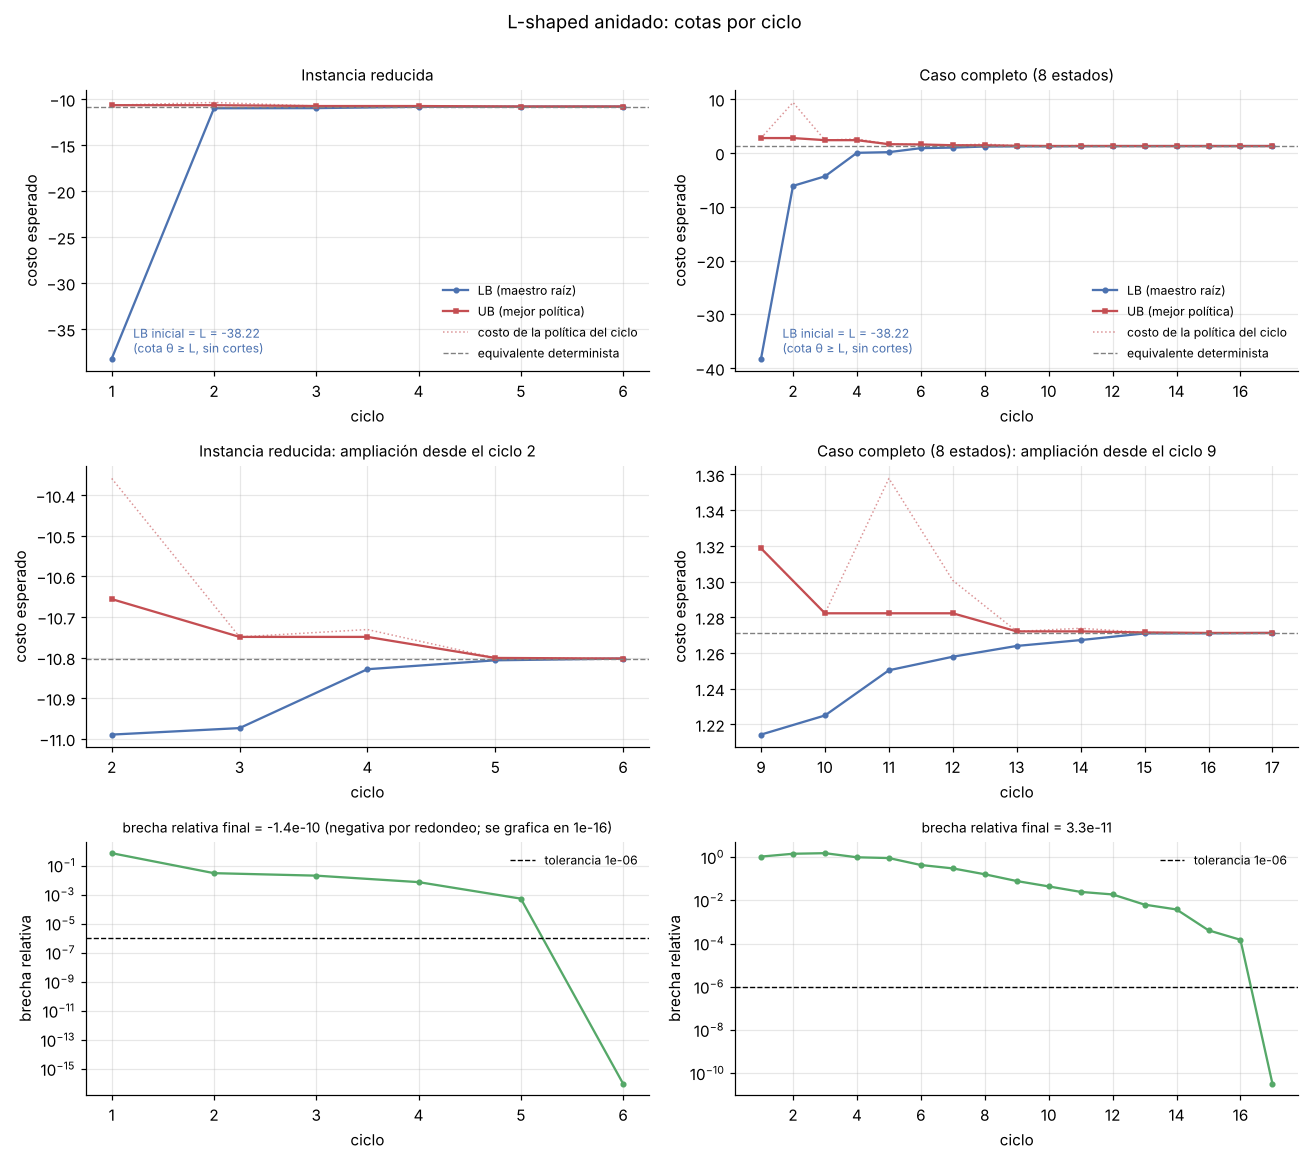

,LB,policy_cost,UB,rel_gap,cuts_total,lp_solved,time_s,cuts_added
iteration,,,,,,,,
1,-38.221687,2.7532278,2.7532278,1.0720331,0,73,0.1191152,73
2,-6.1328864,9.3687707,2.7532278,1.4489285,73,730,1.2203301,61
3,-4.3574071,2.3651288,2.3651288,1.5427835,134,1387,2.3390788,46
4,0.011977015,2.5944584,2.3651288,0.994936,180,2044,3.5090124,28
5,0.13431094,1.6124751,1.6124751,0.91670511,208,2701,4.5804521,33
6,0.88071004,1.5645017,1.5645017,0.43706673,241,3358,5.6092457,28
7,0.98433653,1.4158824,1.4158824,0.30478932,269,4015,6.6563483,16
8,1.1853558,1.6416074,1.4158824,0.16281479,285,4672,7.7812502,26
9,1.2142422,1.3186159,1.3186159,0.079153982,311,5329,8.8241066,6


In [10]:
ZOOM_GAP = 0.1   # la fila ampliada empieza en el primer ciclo con brecha relativa <= 10 %
fig, axes = plt.subplots(3, 2, figsize=(12, 10.5), gridspec_kw={"height_ratios": [1, 1, 0.9]})
for col, (obj, name, ref) in enumerate([(ls_red, "Instancia reducida", red_sol["objective"]),
                                        (ls, "Caso completo (8 estados)", full_de_sol["objective"] if full_de_sol else None)]):
    lg = obj.log
    it0 = int(lg.loc[lg["rel_gap"] <= ZOOM_GAP, "iteration"].iloc[0])
    for row, data, title in [(0, lg, name), (1, lg[lg["iteration"] >= it0], f"{name}: ampliación desde el ciclo {it0}")]:
        ax = axes[row, col]
        ax.plot(data["iteration"], data["LB"], "o-", ms=3, label="LB (maestro raíz)", color="#4c72b0")
        ax.plot(data["iteration"], data["UB"], "s-", ms=3, label="UB (mejor política)", color="#c44e52")
        ax.plot(data["iteration"], data["policy_cost"], ":", lw=1, color="#c44e52", alpha=0.6,
                label="costo de la política del ciclo")
        if ref is not None:
            ax.axhline(ref, color="gray", ls="--", lw=0.9, label="equivalente determinista")
        ax.set_title(title, fontsize=10); ax.set_xlabel("ciclo"); ax.set_ylabel("costo esperado")
        if row == 0:
            ax.annotate(f"LB inicial = L = {lg['LB'].iloc[0]:.2f}\n(cota θ ≥ L, sin cortes)",
                        (lg["iteration"].iloc[0], lg["LB"].iloc[0]), textcoords="offset points",
                        xytext=(14, 4), fontsize=8, color="#4c72b0")
            ax.legend(frameon=False, fontsize=8, loc="lower right")
    ax = axes[2, col]
    ax.semilogy(lg["iteration"], np.maximum(lg["rel_gap"], 1e-16), "o-", ms=3, color="#55a868")
    ax.axhline(TOL, color="black", ls="--", lw=0.9, label=f"tolerancia {TOL:g}")
    g_end = lg["rel_gap"].iloc[-1]
    note = " (negativa por redondeo; se grafica en 1e-16)" if g_end < 0 else ""
    ax.set_title(f"brecha relativa final = {g_end:.1e}{note}", fontsize=9)
    ax.set_xlabel("ciclo"); ax.set_ylabel("brecha relativa"); ax.legend(frameon=False, fontsize=8)
for ax in axes.ravel():
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
fig.suptitle("L-shaped anidado: cotas por ciclo", y=1.0)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "04_lshaped_bounds.png", bbox_inches="tight"); plt.show()

with pd.option_context("display.float_format", "{:.8g}".format):
    display(ls.log.set_index("iteration"))

## 8. Política obtenida y registro definitivo

De todas las políticas que construyó el algoritmo, se conserva la de menor costo esperado, es decir, la que dio el mejor UB. Para cada uno de los 73 nodos de decisión se guardan su historia, su riqueza $V^{t,*}_k$, los montos invertidos $x^{t,*}_{i,k}$ y las proporciones $f^t_{i,k} = x^{t,*}_{i,k}/V^{t,*}_k$, que son las que se aplicarán en 2026. También se guardan los resultados de las 512 hojas y la regla con la que la política se aplicará a los datos reales.

Antes de guardar se comprueba que ninguna inversión sea negativa, que los montos de cada nodo sumen su riqueza y que esa riqueza sea exactamente la que dejaron las inversiones del padre. El archivo queda acompañado de su huella digital, y el notebook 06 la verifica antes de abrir cualquier dato de 2026; así se garantiza que la política no se modificó después de ver lo que ocurrió.

In [11]:
rows = []
for t in range(1, ls.H):
    for k in ls.nodes[t]:
        x = ls.best_policy[(t, k)]
        V = float(x.sum())
        rows.append({"t": t, "k": k, "history": ls.history[(t, k)], "p_cum": ls.p[(t, k)], "V": V,
                     **{f"x_{tk}": x[i] for i, tk in enumerate(TICKERS)},
                     **{f"f_{tk}": x[i] / V for i, tk in enumerate(TICKERS)}})
policy = pd.DataFrame(rows)

assert (policy[[f"x_{tk}" for tk in TICKERS]] >= -1e-9).all().all(), "Hay inversiones negativas."
assert abs(policy.loc[policy["t"] == 1, "V"].item() - B_CAP) < 1e-7, "La raíz no invierte b."
for r in policy[policy["t"] > 1].itertuples():
    key = (r.t, r.k)
    inherited = float(ls.R[key] @ ls.best_policy[(r.t - 1, ls.parent[key])])
    assert abs(inherited - r.V) < 1e-6, f"Balance violado en {key}."
fsum = policy[[f"f_{tk}" for tk in TICKERS]].sum(axis=1)
assert np.allclose(fsum, 1.0) and (policy[[f"f_{tk}" for tk in TICKERS]] >= -1e-9).all().all()
assert len(policy) == sum(len(ls.nodes[t]) for t in range(1, ls.H))
cost_check, _ = ls.evaluate_policy(ls.best_policy)
assert abs(cost_check - UB_f) < 1e-9
print(f"✔ {len(policy)} nodos: inversiones no negativas, balances heredados correctos, proporciones en [0,1] que suman 1.")
print(f"✔ Costo esperado de la política guardada (512 hojas) = {cost_check:.10f} = UB")

print("\nRaíz y nodos de etapa 2 (proporciones):")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(policy[policy["t"] <= 2].set_index(["t", "k"]))

✔ 73 nodos: inversiones no negativas, balances heredados correctos, proporciones en [0,1] que suman 1.
✔ Costo esperado de la política guardada (512 hojas) = 1.2711985137 = UB

Raíz y nodos de etapa 2 (proporciones):


history  p_cum        V   x_SPY  x_LQD   x_GLD  f_SPY  f_LQD  f_GLD
t k                                                                    
1 1    raíz 1.0000 100.0000 84.2273 0.0000 15.7727 0.8423 0.0000 0.1577
2 1     AAA 0.4844 106.9771 74.6236 0.0000 32.3535 0.6976 0.0000 0.3024
  2     AAB 0.0938 105.2606 77.8735 0.0000 27.3872 0.7398 0.0000 0.2602
  3     ABA 0.0469 108.2497 85.1168 0.0000 23.1328 0.7863 0.0000 0.2137
  4     ABB 0.1719 102.5443 71.4172 0.0000 31.1271 0.6965 0.0000 0.3035
  5     BAA 0.0469  93.7815 93.7815 0.0000  0.0000 1.0000 0.0000 0.0000
  6     BAB 0.0469  96.5062 81.7771 0.0000 14.7292 0.8474 0.0000 0.1526
  7     BBA 0.0625  92.6050 92.6050 0.0000  0.0000 1.0000 0.0000 0.0000
  8     BBB 0.0469  92.2010 92.2010 0.0000  0.0000 1.0000 0.0000 0.0000

In [12]:
policy_csv = POLICY_DIR / "lshaped_policy_73_nodes.csv"
leaves_csv = POLICY_DIR / "lshaped_leaves_512.csv"
policy.to_csv(policy_csv, index=False, float_format="%.12g")
ls.best_leaves.to_csv(leaves_csv, index=False, float_format="%.12g")

policy_meta = {
    "description": "Política óptima de L-shaped anidado (caso completo), congelada antes de usar datos de 2026",
    "frozen_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "calibration_parameters_sha256": params_hash,
    "tree_csv_sha256": tree_meta["csv_sha256"],
    "method": "L-shaped anidado, recorridos completos, un corte agregado por nodo y pasada",
    "solver": f"scipy.optimize.linprog(method='highs'), scipy {scipy.__version__}",
    "RP_expected_cost": UB_f, "LB": LB_f, "rel_gap": gap_f, "tolerance": TOL,
    "iterations": int(len(ls.log)), "best_policy_iteration": int(ls.best_iter),
    "cuts_total": int(ls.log["cuts_total"].iloc[-1]), "cuts_by_stage": {str(t): v for t, v in cuts_by_stage.items()},
    "lp_solved": int(summary.at["LP resueltos", "caso completo"]),  # sin los LP del chequeo de duales "time_s": ls.elapsed,
    "cut_rule": "Se agrega un corte solo si es violado en la solución actual (clase 7, diapositiva 46)",
    "final_backward_violated_cuts": int(ls.final_violated),
    "application_rule": ("Extensión por proporciones (sección 5.2): la terna de signos observada (SPY, LQD, GLD; "
                         "B si r < 0, A si r ≥ 0) determina la historia y el nodo; las proporciones f de ese nodo se "
                         "aplican a la riqueza realmente disponible. La riqueza se actualiza con los factores reales. "
                         "No se reestiman parámetros ni se reoptimiza con datos de 2026."),
    "fallback_rule": ("Solo si se eliminó un estado en calibración y aparece en validación: repartir la riqueza en "
                      "partes iguales entre los tres activos durante los períodos restantes."),
    "removed_states": params["removed_states"],
    "policy_csv": str(policy_csv.relative_to(ROOT)), "policy_csv_sha256": sha256_of(policy_csv),
    "leaves_csv": str(leaves_csv.relative_to(ROOT)), "leaves_csv_sha256": sha256_of(leaves_csv),
}
meta_path = POLICY_DIR / "lshaped_policy.json"
meta_path.write_text(json.dumps(policy_meta, indent=2, ensure_ascii=False), encoding="utf-8")
(POLICY_DIR / "lshaped_policy.sha256").write_text(sha256_of(meta_path) + "\n")

# Historial, cortes y aportes para el informe y los anexos
ls_red.log.to_csv(LS_DIR / "reduced_convergence.csv", index=False, float_format="%.12g")
ls.log.to_csv(LS_DIR / "full_convergence.csv", index=False, float_format="%.12g")
pd.DataFrame(ls.contributions).to_csv(LS_DIR / "full_cut_contributions.csv", index=False, float_format="%.12g")
pd.DataFrame([{"t": t, "k": k, "iteration": c["iteration"], "alpha": c["alpha"],
               **{f"beta_{tk}": c["beta"][i] for i, tk in enumerate(TICKERS)},
               **{f"xeval_{tk}": c["x_eval"][i] for i, tk in enumerate(TICKERS)}}
              for (t, k), cl in ls.cuts.items() for c in cl]).to_csv(LS_DIR / "full_cuts.csv", index=False,
                                                                     float_format="%.12g")
summary.to_csv(LS_DIR / "summary.csv", float_format="%.12g")
pd.DataFrame(ls.cut_log).to_csv(LS_DIR / "full_cut_violation_log.csv", index=False, float_format="%.12g")

print("Política congelada:")
for p in [policy_csv, leaves_csv, meta_path, POLICY_DIR / "lshaped_policy.sha256"]:
    print("  ", p.relative_to(ROOT))
print("Registros de L-shaped:")
for p in sorted(LS_DIR.iterdir()):
    print("  ", p.relative_to(ROOT))
print("  ", (FIGURES_DIR / "04_lshaped_bounds.png").relative_to(ROOT))
print(f"\nSHA-256 de la política: {sha256_of(meta_path)}")

Política congelada:
   results/policy/lshaped_policy_73_nodes.csv
   results/policy/lshaped_leaves_512.csv
   results/policy/lshaped_policy.json
   results/policy/lshaped_policy.sha256
Registros de L-shaped:
   results/lshaped/full_convergence.csv
   results/lshaped/full_cut_contributions.csv
   results/lshaped/full_cut_violation_log.csv
   results/lshaped/full_cuts.csv
   results/lshaped/reduced_convergence.csv
   results/lshaped/summary.csv
   results/figures/04_lshaped_bounds.png

SHA-256 de la política: 23d32a55db9ba214d1cceb8221209c4f7078ffb872c1c52bdd9a5f08460f14f0
